In [1]:
from datasets import load_dataset_builder, load_dataset, get_dataset_split_names, load_from_disk
import matplotlib.pyplot as plt
import numpy as np
import json
from pathlib import Path
from huggingface_hub import hf_hub_download
import evaluate
from transformers import AutoImageProcessor
from torchvision.transforms import ColorJitter
import numpy as np
import torch
from torch import nn
from transformers import AutoModelForSemanticSegmentation, TrainingArguments, Trainer

import warnings
warnings.filterwarnings("ignore")

c:\Users\dzky17\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\dzky17\AppData\Local\Programs\Python\Python313\Lib\site-packages\transformers\utils\hub.py:111: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


In [2]:
datasets = load_from_disk("./data/scene_parse_150/")
datasets

DatasetDict({
    test: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 3352
    })
    validation: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 2000
    })
    train: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 20210
    })
})

In [3]:
ds = datasets['train'].select(range(500))
ds = ds.train_test_split(test_size=0.2, seed=42)
ds

DatasetDict({
    train: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 400
    })
    test: Dataset({
        features: ['image', 'annotation', 'scene_category'],
        num_rows: 100
    })
})

In [4]:
index = np.random.randint(0, len(ds['train']))
ds['train'][index]

{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=450x312>,
 'annotation': <PIL.PngImagePlugin.PngImageFile image mode=L size=450x312>,
 'scene_category': 467}

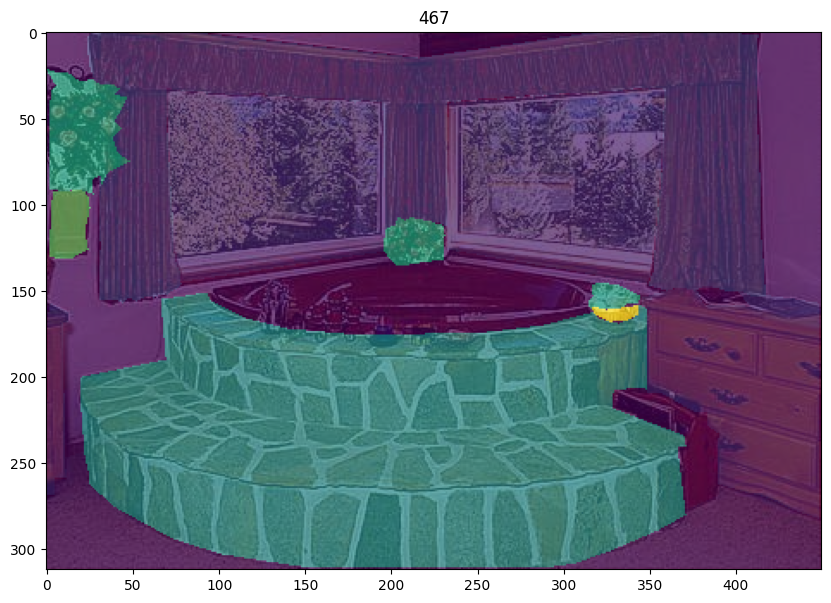

In [5]:
def visualize_seg_mask(image, mask, title=None):
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    ax.imshow(np.asarray(image))
    ax.imshow(np.asarray(mask), alpha=0.7)
    ax.set_title(title if title else "Segmentation Mask Overlay")
    
    plt.show()

visualize_seg_mask(ds['train'][index]['image'], ds['train'][index]['annotation'], title=ds['train'][index]['scene_category'])

In [6]:
repo_id = "huggingface/label-files"
filename = "ade20k-id2label.json"
id2label = json.loads(Path(hf_hub_download(repo_id, filename, repo_type="dataset")).read_text())
id2label = {int(k): v for k, v in id2label.items()}
label2id = {v: k for k, v in id2label.items()}
num_labels = len(id2label)

In [7]:
train_ds = ds["train"]
test_ds = ds["test"]

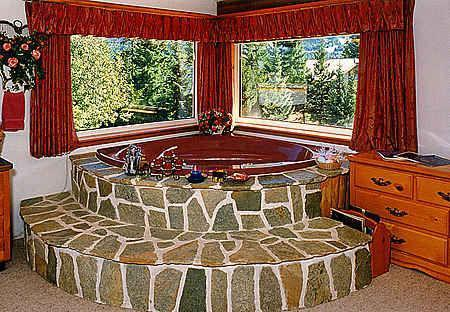

In [8]:
train_ds[index]['image']

In [9]:
checkpoint = "openmmlab/upernet-convnext-small"
image_processor = AutoImageProcessor.from_pretrained(
    checkpoint,
    do_reduce_labels=True,
    size={"height": 256, "width": 256}   # resolusi lebih kecil dari default 512
)

Fetching 1 files: 100%|██████████| 1/1 [00:00<00:00, 10485.76it/s]
Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


In [10]:
jitter = ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.1)

In [11]:
def train_transforms(example_batch):
    images = [jitter(x) for x in example_batch["image"]]
    labels = [x for x in example_batch["annotation"]]
    inputs = image_processor(images, labels)
    return inputs


def val_transforms(example_batch):
    images = [x for x in example_batch["image"]]
    labels = [x for x in example_batch["annotation"]]
    inputs = image_processor(images, labels)
    return inputs

In [12]:
train_ds.set_transform(train_transforms)
test_ds.set_transform(val_transforms)

In [13]:
metric = evaluate.load("mean_iou")

def compute_metrics(eval_pred):
    with torch.no_grad():
        logits, labels = eval_pred
        logits_tensor = torch.from_numpy(logits)
        logits_tensor = nn.functional.interpolate(
            logits_tensor,
            size=labels.shape[-2:],
            mode="bilinear",
            align_corners=False,
        ).argmax(dim=1)

        pred_labels = logits_tensor.detach().cpu().numpy()
        metrics = metric.compute(
            predictions=pred_labels,
            references=labels,
            num_labels=num_labels,
            ignore_index=255,
            reduce_labels=False,
        )
        for key, value in metrics.items():
            if isinstance(value, np.ndarray):
                metrics[key] = value.tolist()
        return metrics

In [14]:
model = AutoModelForSemanticSegmentation.from_pretrained(checkpoint, id2label=id2label, label2id=label2id)

In [15]:
type(train_ds), type(test_ds)

(datasets.arrow_dataset.Dataset, datasets.arrow_dataset.Dataset)

In [16]:
training_args = TrainingArguments(
    output_dir="upernet-convnext-small",
    learning_rate=6e-5,
    num_train_epochs=1,            # cukup 1 dulu untuk tes
    max_steps=500,                 # batasi step biar cepat
    per_device_train_batch_size=2, # aman di RAM kecil
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=1,
    save_total_limit=1,            # hanya simpan checkpoint terakhir
    eval_strategy="steps",
    save_strategy="steps",
    save_steps=500,                # simpan sekali di akhir
    eval_steps=500,                # evaluasi sekali di akhir
    logging_steps=50,
    eval_accumulation_steps=1,
    remove_unused_columns=False,
    push_to_hub=False,
    fp16=False,                    # matikan, karena di CPU/Windows sering bermasalah
    dataloader_num_workers=0       # aman di Windows, tidak error worker
)


trainer = Trainer(
    model=model, # model yang digunakan
    args=training_args, # argumen training
    train_dataset=train_ds, # dataset training
    eval_dataset=test_ds, # dataset evaluasi
    compute_metrics=compute_metrics, # fungsi untuk menghitung metriks
)


trainer.train()

Step,Training Loss,Validation Loss,Mean Iou,Mean Accuracy,Overall Accuracy,Per Category Iou,Per Category Accuracy
500,0.580700,0.615797,0.465975,0.595206,0.870345,"[0.7723217930921858, 0.8485157911841172, 0.92732203504589, 0.8124747892213589, 0.7266165180816785, 0.8285383813371563, 0.8249371942350919, 0.8287769877517127, 0.5882334516600543, 0.8889211191166838, 0.6911877736067638, 0.5984532106649249, 0.7778267577694512, 0.6745940394184625, 0.4551221140758622, 0.5206692913385826, 0.7028575169388891, 0.602912005078156, 0.7329962170925655, 0.46595385481148, 0.6687828176451392, 0.9099117447386287, 0.5459852406652715, 0.5843939832224472, 0.6447038048726651, 0.771223850041584, 0.9193394488479089, 0.6603360985001545, 0.19345002823263693, 0.8849230191513331, 0.1940650023551578, 0.9330721817911778, 0.5026206707546846, 0.5796211355567649, 0.65420209164096, 0.8844118986720858, 0.4536125830599714, 0.8399710958561463, 0.018743834265044394, 0.5155409254921821, 0.16952573158425832, 0.14996162701458174, 0.5581761006289309, 0.44077091820745845, 0.8964100222590035, 0.8330405723833597, 0.9083936861652739, 0.7043387712599791, 0.6814245507685647, 0.5669928490779074, 0.7850807635829662, 0.43935926773455375, 0.21323050184662176, 0.5937296795169531, nan, 0.0, 0.7331040550267935, 0.5017661603673613, 0.013140847677216362, 0.47113337507827174, 0.848331135233844, nan, 0.5192724122996968, 0.7886891714160456, 0.38561215370866847, 0.0, 0.4884985361773317, 0.27732558139534885, nan, 0.16981132075471697, 0.6438356164383562, 0.5525606469002695, 0.4159009188973232, 0.0, 0.3845411959217415, nan, nan, 0.0, 0.8355646469633914, nan, nan, 0.67367594450746, 0.299525683721869, 0.0, 0.0, 0.6271767810026385, 0.0, 0.06972477064220184, 0.8363148655845052, 0.49222189609627237, 0.7306935563207083, nan, 0.8848216806248236, 0.15097469929489837, nan, 0.0, nan, 0.0, 0.0, 0.07234600262123198, 0.3132172377818795, 0.5109306683322923, 0.3168103448275862, nan, 0.29740791268758526, 0.7326696832579186, 0.0, 0.9152061055153747, nan, nan, 0.2735068451933203, nan, 0.3720543387856945, nan, 0.8983953590935305, 0.0, nan, nan, 0.7338271604938271, 0.0, nan, 0.0, 0.9164877872426961, 0.0, 0.5652349263964509, 0.0, 0.0, 0.32766125840918087, nan, 0.5372612948299953, 0.8035680394761814, 0.3753064408290617, 0.0, 0.2842699970264645, 0.3795918367346939, 0.27788554801163917, 0.4929283906505881, 0.6920401854714064, 0.33507488679902475, 0.0, nan, 0.0, 0.210727969348659, 0.10126254451278731, 0.0, 0.5406062339147841, nan, 0.0, 0.4717514124293785, 0.0]","[0.8700959306063271, 0.9272380944694091, 0.9604945136139017, 0.890104755281231, 0.8255969856346652, 0.8623092573753814, 0.9061435925573289, 0.9630682246513381, 0.7054352861632464, 0.9409195356760826, 0.7853933295361053, 0.6966721133778777, 0.8909953126886725, 0.8528285835814547, 0.6049703010855465, 0.6189986525778314, 0.798727867876804, 0.7542808927419221, 0.9587982832618026, 0.5170886794595209, 0.8396275605214153, 0.9831291718623927, 0.7715775546735154, 0.9019979908471928, 0.8105595448711278, 0.9613237639553429, 0.958116317307787, 0.8860149896348269, 0.29688041594454073, 0.9994910401866186, 0.31070889894419307, 0.9982917866719635, 0.7782315811807139, 0.7799086439555075, 0.6891495601173021, 0.9370406117751875, 0.48385070877444825, 0.9721444884042587, 0.05637982195845697, 0.6502714787607793, 0.16952573158425832, 0.15163743597702933, 0.6727797539215115, 0.5332701421800948, 0.9911649627666288, 0.9725403891361977, 0.9963540817989246, 0.9166139669346824, 0.6814245507685647, 0.8880047155909225, 0.9352739486390036, 0.9685111586670743, 0.38086922778424526, 0.9129410084273675, nan, nan, 0.743571022957735, 0.5094136632598171, 0.013492968453059672, 0.5007320644216691, 0.96642588847154, nan, 0.6739741427768409, 0.900670872133774, 0.6118397731300957, nan, 0.5274328290810567, 0.47439085032322226, nan, 0.16981132075471697, 0.9972082635399219, 0.6339612032611751, 0.43447412353923204, nan, 0.8781562180445214, nan, nan, nan, 0.999780561088417, nan, nan, 0.7785620651406675, 0.4

TrainOutput(global_step=500, training_loss=0.7883261413574219, metrics={'train_runtime': 1646.358, 'train_samples_per_second': 0.607, 'train_steps_per_second': 0.304, 'total_flos': 9.6586270507008e+16, 'train_loss': 0.7883261413574219, 'epoch': 2.5})

In [17]:
model.save_pretrained("models/upernet-convnext-small")